In [1]:
!pip install openpyxl


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
df=pd.read_excel("../data/spam.csv.xlsx")
print("shape:",df.shape)

shape: (5572, 2)


In [3]:
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   str   
 1   Message   5572 non-null   object
dtypes: object(1), str(1)
memory usage: 104.2+ KB


In [5]:
print(df["Category"].value_counts())

Category
ham     4825
spam     747
Name: count, dtype: int64


In [6]:
print(df["Category"].value_counts(normalize=True)*100)

Category
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


## Problem Statement
Build a machine learning model that classifies a text message as **spam** or **ham**
based on its content.

**Questions this dataset can help answer:**
- Can we automatically detect unwanted or scam messages?
- What do spam messages look like compared to normal ones (length, words, symbols)?
- Which words or patterns are strong signals of spam?

**Type of problem:** Binary classification (spam = 1, ham = 0)

# Data Cleaning and Manipulation


In [7]:
#missing values
print("Missing values:")
print(df.isnull().sum())
print()
print("Data types:")
print(df.dtypes)

Missing values:
Category    0
Message     0
dtype: int64

Data types:
Category       str
Message     object
dtype: object


In [8]:
#duplicates
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates(keep="first").reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)


Duplicate rows: 415
Shape after removing duplicates: (5157, 2)


In [9]:
df["Label"] = df["Category"].map({"ham": 0, "spam": 1})

print(df[["Category", "Label"]].head())
print()
print(df["Label"].value_counts())


  Category  Label
0      ham      0
1      ham      0
2     spam      1
3      ham      0
4      ham      0

Label
0    4516
1     641
Name: count, dtype: int64


In [10]:
print(df.isnull().sum())     
print(df.shape)
df.head()

Category    0
Message     0
Label       0
dtype: int64
(5157, 3)


,Category,Message,Label
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [11]:
df["Message"] = df["Message"].astype(str)

df["char_count"]    = df["Message"].apply(len)
df["word_count"]    = df["Message"].apply(lambda x: len(x.split()))
df["digit_count"]   = df["Message"].apply(lambda x: sum(c.isdigit() for c in x))
df["upper_count"]   = df["Message"].apply(lambda x: sum(c.isupper() for c in x))
df["special_count"] = df["Message"].apply(lambda x: sum(not c.isalnum() and not c.isspace() for c in x))

df.head()

,Category,Message,Label,char_count,word_count,digit_count,upper_count,special_count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20,0,3,9
1,ham,Ok lar... Joking wif u oni...,0,29,6,0,2,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28,25,10,6
3,ham,U dun say so early hor... U c already then say...,0,49,11,0,2,6
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13,0,2,2


In [12]:
print(df.dtypes)
print()
print(df.describe())

Category           str
Message            str
Label            int64
char_count       int64
word_count       int64
digit_count      int64
upper_count      int64
special_count    int64
dtype: object

             Label   char_count   word_count  digit_count  upper_count  \
count  5157.000000  5157.000000  5157.000000  5157.000000   5157.00000   
mean      0.124297    79.228040    15.410704     2.165212      5.45414   
std       0.329952    58.451149    11.118902     5.931815     11.81049   
min       0.000000     2.000000     1.000000     0.000000      0.00000   
25%       0.000000    36.000000     7.000000     0.000000      1.00000   
50%       0.000000    61.000000    12.000000     0.000000      2.00000   
75%       0.000000   118.000000    22.000000     1.000000      4.00000   
max       1.000000   910.000000   171.000000    40.000000    140.00000   

       special_count  
count    5157.000000  
mean        4.142137  
std         4.457079  
min         0.000000  
25%         2.00000

In [13]:
#compare spam vs ham
num_cols = ["char_count", "word_count", "digit_count", "upper_count", "special_count"]

print(df.groupby("Category")[num_cols].mean().round(2))

          char_count  word_count  digit_count  upper_count  special_count
Category                                                                 
ham            70.95       14.24         0.30         4.02           3.87
spam          137.54       23.66        15.33        15.55           6.04


# visualization

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

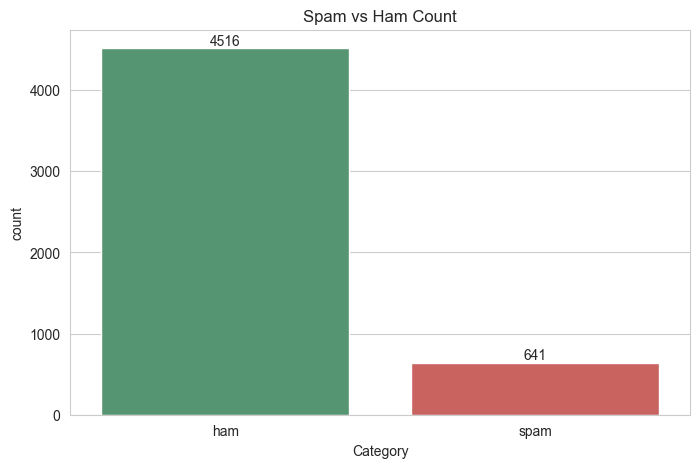

In [15]:
#categorical variable
ax = sns.countplot(data=df, x="Category", hue="Category", palette=["#4C9F70", "#D9534F"], legend=False)
plt.title("Spam vs Ham Count")

for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")

plt.savefig("../outputs/class_distribution.png", bbox_inches="tight")
plt.show()

# pie chart of class share

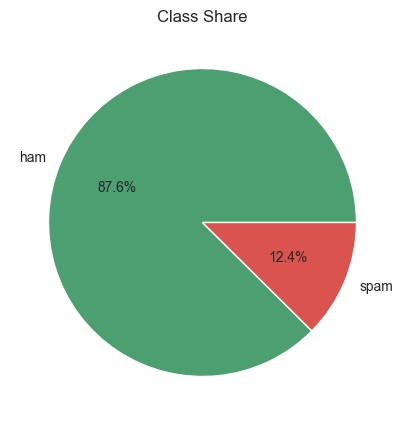

In [16]:
df["Category"].value_counts().plot.pie(autopct="%1.1f%%", colors=["#4C9F70", "#D9534F"], ylabel="")
plt.title("Class Share")
plt.show()

# distribution of message length

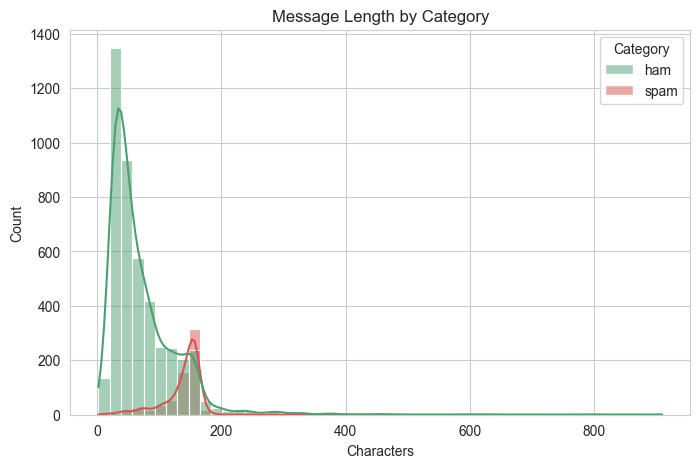

In [17]:
sns.histplot(data=df, x="char_count", hue="Category", bins=50, kde=True,
             palette=["#4C9F70", "#D9534F"])
plt.title("Message Length by Category")
plt.xlabel("Characters")
plt.savefig("../outputs/char_count_hist.png", bbox_inches="tight")
plt.show()

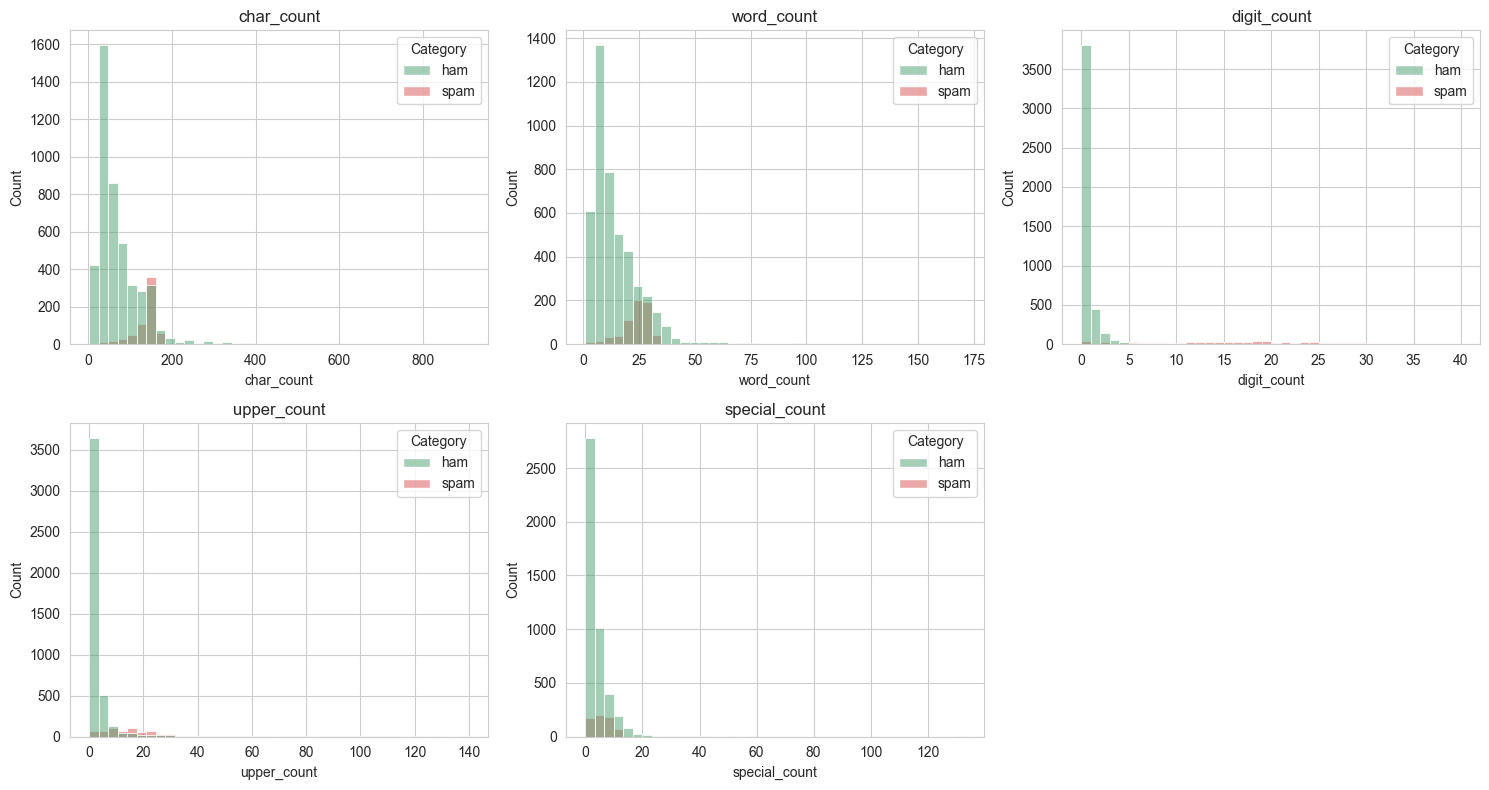

In [18]:
num_cols = ["char_count", "word_count", "digit_count", "upper_count", "special_count"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue="Category", bins=40,
                 palette=["#4C9F70", "#D9534F"], ax=axes[i])
    axes[i].set_title(col)

axes[-1].axis("off")   # hide the empty 6th panel
plt.tight_layout()
plt.savefig("../outputs/numeric_distributions.png", bbox_inches="tight")
plt.show()

# boxplot for outliers


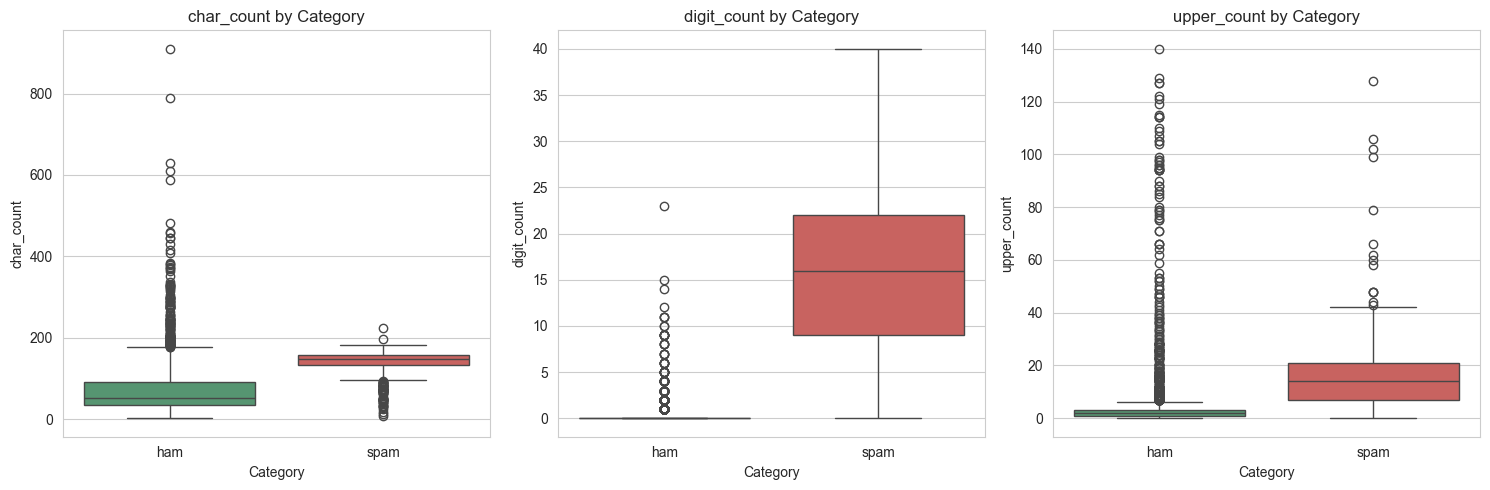

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["char_count", "digit_count", "upper_count"]):
    sns.boxplot(data=df, x="Category", y=col, hue="Category",
                palette=["#4C9F70", "#D9534F"], legend=False, ax=ax)
    ax.set_title(f"{col} by Category")

plt.tight_layout()
plt.savefig("../outputs/boxplots.png", bbox_inches="tight")
plt.show()


#correlation heatmap



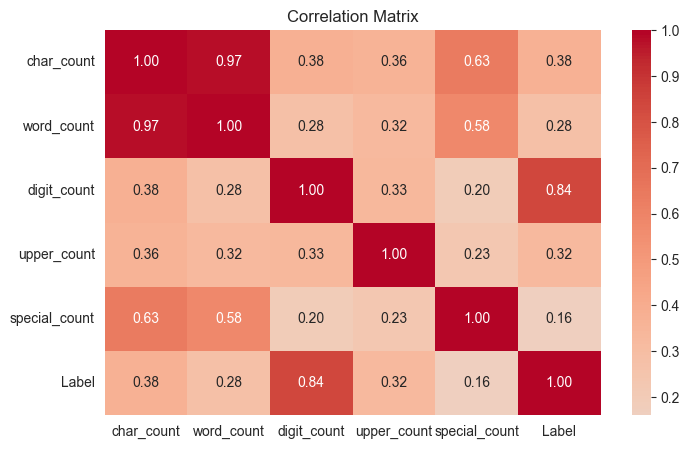

In [20]:
corr = df[num_cols + ["Label"]].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.savefig("../outputs/correlation_heatmap.png", bbox_inches="tight")
plt.show()

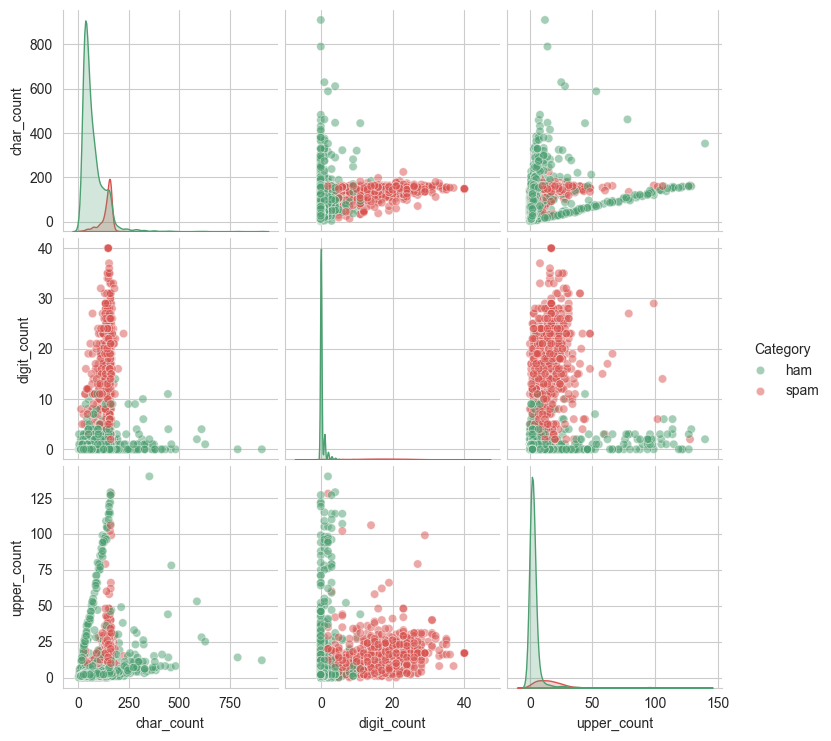

In [21]:
sns.pairplot(df, vars=["char_count", "digit_count", "upper_count"],
             hue="Category", palette=["#4C9F70", "#D9534F"], plot_kws={"alpha": 0.5})
plt.savefig("../outputs/pairplot.png", bbox_inches="tight")
plt.show()

# most common words in spam vs ham

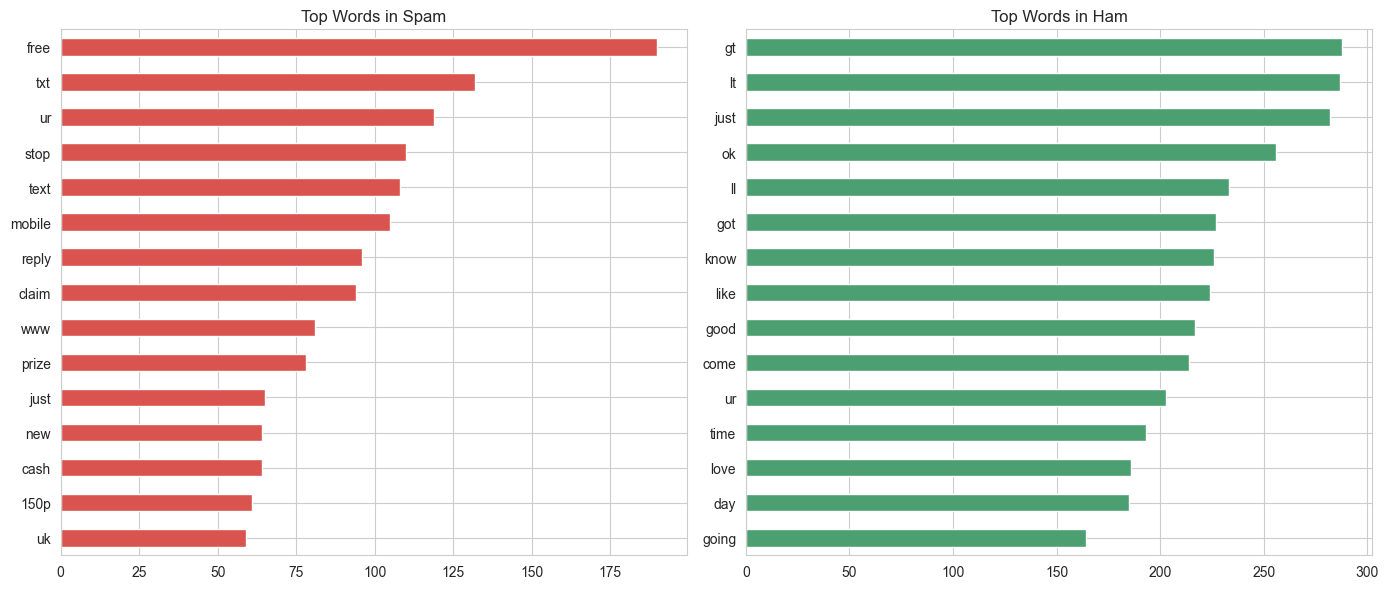

In [22]:
from sklearn.feature_extraction.text import CountVectorizer

def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english")
    counts = cv.fit_transform(texts)
    freq = counts.sum(axis=0).A1
    words = cv.get_feature_names_out()
    return pd.Series(freq, index=words).sort_values(ascending=False).head(n)

spam_words = top_words(df[df["Label"] == 1]["Message"])
ham_words  = top_words(df[df["Label"] == 0]["Message"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

spam_words.sort_values().plot.barh(ax=axes[0], color="#D9534F")
axes[0].set_title("Top Words in Spam")

ham_words.sort_values().plot.barh(ax=axes[1], color="#4C9F70")
axes[1].set_title("Top Words in Ham")

plt.tight_layout()
plt.savefig("../outputs/top_words.png", bbox_inches="tight")
plt.show()

## Sprint 0 Summary
- The dataset is imbalanced: about 88% ham and 12% spam.
- Spam messages are longer (about 2x characters).
- Digits are the strongest signal: spam averages about 15 digits vs 0.3 in ham.
- Spam has more uppercase letters and special characters.
- char_count and word_count are highly correlated with each other.
- Spam vocabulary is promotional (free, call, claim, prize); ham is conversational.
- Because of the class imbalance, we will evaluate with precision, recall and F1, not accuracy alone.

## Preprocessing

In [23]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
# cleaning
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words]
    return " ".join(words)

df["clean_message"] = df["Message"].apply(clean_text)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [25]:
print(df.columns.tolist())
print(df.shape)   # should be (5157, 9)
df[["Message", "clean_message"]].head()

['Category', 'Message', 'Label', 'char_count', 'word_count', 'digit_count', 'upper_count', 'special_count', 'clean_message']
(5157, 9)


,Message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


# train-test split

In [26]:
from sklearn.model_selection import train_test_split

num_cols = ["char_count", "word_count", "digit_count", "upper_count", "special_count"]

X = df[["clean_message"] + num_cols]
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Train spam %:", round(y_train.mean() * 100, 2))
print("Test spam %: ", round(y_test.mean() * 100, 2))

Train: (4125, 6)  Test: (1032, 6)

Train spam %: 12.44
Test spam %:  12.4


In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train["clean_message"])
X_test_tfidf  = tfidf.transform(X_test["clean_message"])

print("TF-IDF train:", X_train_tfidf.shape)
print("TF-IDF test: ", X_test_tfidf.shape)

TF-IDF train: (4125, 5000)
TF-IDF test:  (1032, 5000)


In [28]:
# scale numericala features
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num  = scaler.transform(X_test[num_cols])

In [29]:
from scipy.sparse import hstack, csr_matrix

X_train_final = hstack([X_train_tfidf, csr_matrix(X_train_num)])
X_test_final  = hstack([X_test_tfidf,  csr_matrix(X_test_num)])

print("Final train:", X_train_final.shape)
print("Final test: ", X_test_final.shape)

Final train: (4125, 5005)
Final test:  (1032, 5005)


In [30]:
#save
import joblib
joblib.dump(tfidf,  "../models/tfidf.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

['../models/scaler.pkl']

# model development

In [31]:
#training
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix


In [32]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
}

In [33]:
# train
for name, model in models.items():
    model.fit(X_train_final, y_train)
    print(f"{name} trained")
    

Naive Bayes trained
Logistic Regression trained
Linear SVM trained
Random Forest trained


In [34]:
# compare models on test set
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_final)
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1
2,Linear SVM,0.9874,0.9675,0.9297,0.9482
1,Logistic Regression,0.9845,0.9746,0.8984,0.9350
3,Random Forest,0.9806,1.0000,0.8438,0.9153
0,Naive Bayes,0.9748,1.0000,0.7969,0.8870


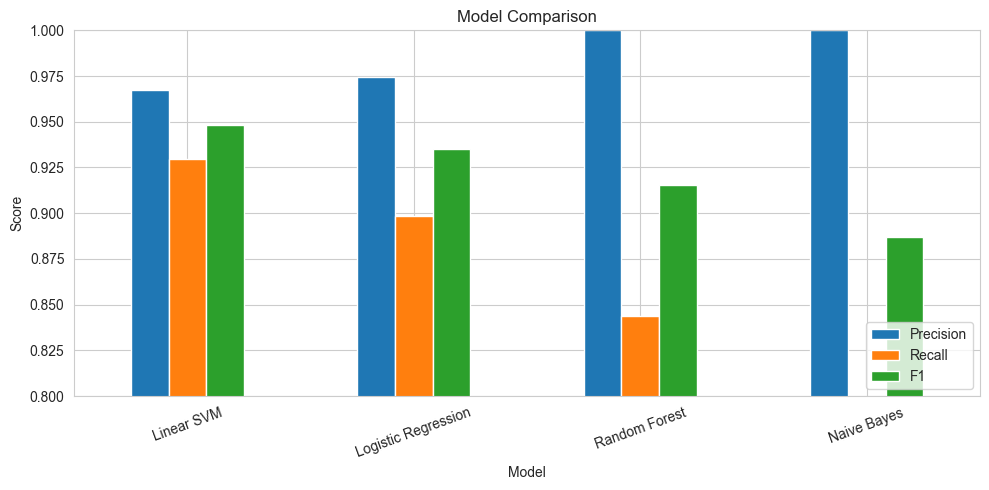

In [35]:
results_df.set_index("Model")[["Precision", "Recall", "F1"]].plot.bar(figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0.8, 1.0)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/model_comparison.png", bbox_inches="tight")
plt.show()

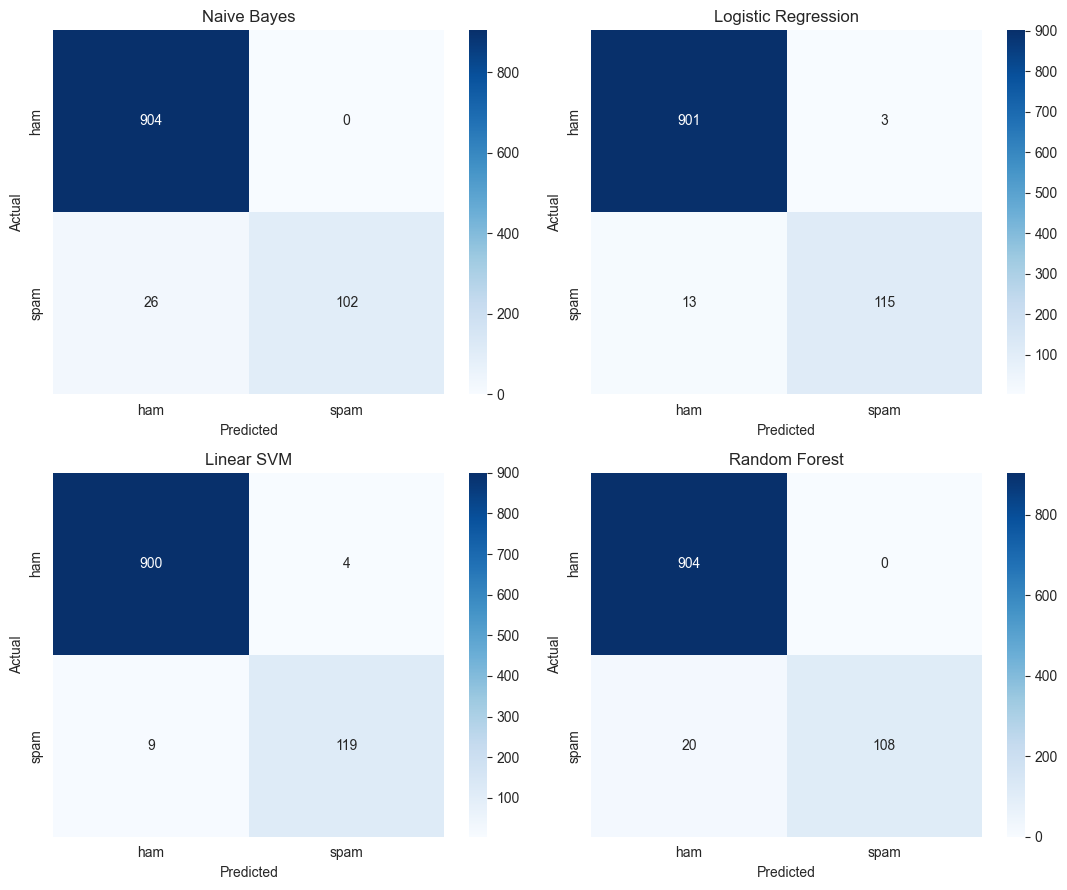

In [36]:
# confusipn matrix
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_final))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("../outputs/confusion_matrices.png", bbox_inches="tight")
plt.show()


In [37]:
# best model
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

print("Best model:", best_name)
print()
print(classification_report(y_test, best_model.predict(X_test_final), target_names=["ham", "spam"]))

Best model: Linear SVM

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       904
        spam       0.97      0.93      0.95       128

    accuracy                           0.99      1032
   macro avg       0.98      0.96      0.97      1032
weighted avg       0.99      0.99      0.99      1032



In [38]:
import joblib

joblib.dump(best_model, "../models/model.pkl")
print(f"Saved {best_name} to ../models/model.pkl")

Saved Linear SVM to ../models/model.pkl


# architecture

In [39]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
import tensorflow as tf
print(tf.__version__)

2.21.0


# Sprint 3: Architecture Development (NLP)

In [41]:
train_text = df.loc[X_train.index,"Message"].str.lower().tolist()
test_text  = df.loc[X_test.index,  "Message"].str.lower().tolist()

In [42]:
# convert text to int sequence
from tensorflow.keras.layers import TextVectorization

MAX_WORDS = 5000     # vocabulary size
MAX_LEN   = 50       # words kept per message

vectorizer = TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=MAX_LEN)
vectorizer.adapt(train_text)     # learn vocabulary from train only

X_train_seq = vectorizer(tf.constant(train_text)).numpy()
X_test_seq  = vectorizer(tf.constant(test_text)).numpy()

print("Train:", X_train_seq.shape, " Test:", X_test_seq.shape)
print("Example:", X_train_seq[0][:15])

Train: (4125, 50)  Test: (1032, 50)
Example: [ 496  300    8    1  160  112   36    1 4134   15   60  121    0    0
    0]


In [43]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense

nlp_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])

nlp_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
nlp_model.build(input_shape=(None, MAX_LEN))
nlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,889 (1.32 MB)

 Trainable params: 345,889 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [44]:
# train with class weights
import numpy as np
from tensorflow.keras.callbacks import EarlyStopping

# give spam more weight because it's the minority class
weights = {0: 1.0, 1: (y_train == 0).sum() / (y_train == 1).sum()}

early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = nlp_model.fit(
    X_train_seq, y_train.values,
    validation_split=0.1,
    epochs=20,
    batch_size=32,
    class_weight=weights,
    callbacks=[early_stop],
    verbose=1,
)


Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7379 - loss: 0.7268 - val_accuracy: 0.9637 - val_loss: 0.1432
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9806 - loss: 0.1852 - val_accuracy: 0.9806 - val_loss: 0.0785
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9900 - loss: 0.0963 - val_accuracy: 0.9806 - val_loss: 0.0713
Epoch 4/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9957 - loss: 0.0451 - val_accuracy: 0.9806 - val_loss: 0.0825
Epoch 5/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9960 - loss: 0.0360 - val_accuracy: 0.9709 - val_loss: 0.0966
Epoch 6/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9968 - loss: 0.0267 - val_accuracy: 0.9855 - val_loss: 0.0847


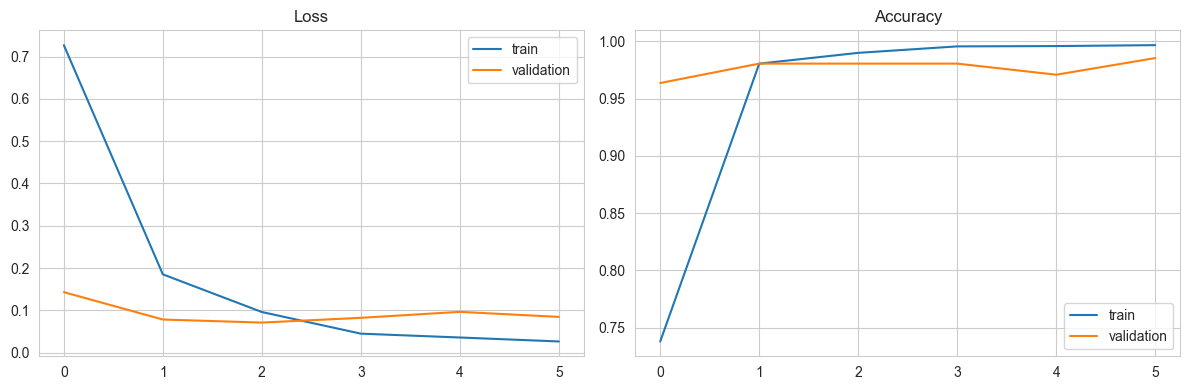

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("../outputs/nlp_training_curves.png", bbox_inches="tight")
plt.show()


# evaluate


In [46]:
y_prob = nlp_model.predict(X_test_seq).ravel()
y_pred_nlp = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred_nlp, target_names=["ham", "spam"]))

nlp_row = {
    "Model": "BiLSTM (NLP)",
    "Accuracy":  accuracy_score(y_test, y_pred_nlp),
    "Precision": precision_score(y_test, y_pred_nlp),
    "Recall":    recall_score(y_test, y_pred_nlp),
    "F1":        f1_score(y_test, y_pred_nlp),
}

final_results = pd.concat([results_df, pd.DataFrame([nlp_row]).round(4)], ignore_index=True)
final_results.sort_values("F1", ascending=False)

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
              precision    recall  f1-score   support

         ham       0.98      0.98      0.98       904
        spam       0.87      0.88      0.88       128

    accuracy                           0.97      1032
   macro avg       0.93      0.93      0.93      1032
weighted avg       0.97      0.97      0.97      1032



,Model,Accuracy,Precision,Recall,F1
0,Linear SVM,0.9874,0.9675,0.9297,0.9482
1,Logistic Regression,0.9845,0.9746,0.8984,0.9350
2,Random Forest,0.9806,1.0000,0.8438,0.9153
3,Naive Bayes,0.9748,1.0000,0.7969,0.8870
4,BiLSTM (NLP),0.9690,0.8692,0.8828,0.8760


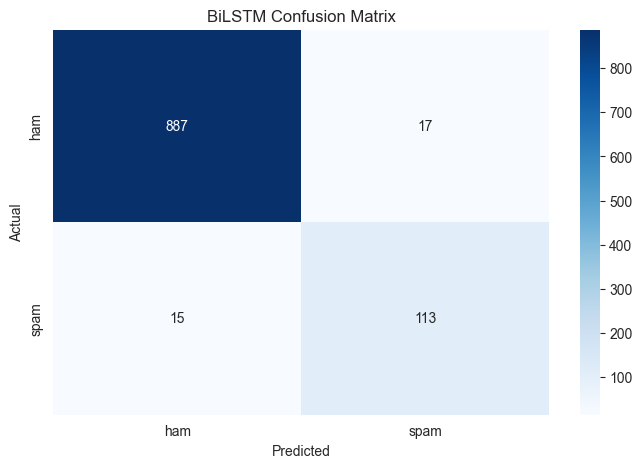

In [47]:
cm = confusion_matrix(y_test, y_pred_nlp)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.title("BiLSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("../outputs/nlp_confusion_matrix.png", bbox_inches="tight")
plt.show()

In [48]:
nlp_model.save("../models/nlp_model.keras")
joblib.dump(vectorizer.get_vocabulary(), "../models/vocab.pkl")

['../models/vocab.pkl']

## Sprint 2 & 3 Conclusion
- Linear SVM (TF-IDF + numeric features) gave the best F1 (0.948) and the best recall (0.930).
- Naive Bayes and Random Forest had perfect precision but missed too much spam (recall 0.80 and 0.84).
- The BiLSTM (F1 0.885) did not beat the classical models: the dataset is small, and it did not use the engineered numeric features.
- Selected model for deployment: Linear SVM.

In [49]:
import joblib
print(type(joblib.load("../models/model.pkl")).__name__)

LinearSVC
